# Starbucks Customer Ordering Patterns

Data from Kaggle: [starbucks-customer-ordering-patterns](https://www.kaggle.com/datasets/likithagedipudi/starbucks-customer-ordering-patterns)


## 1. Load the data

Loads `starbucks_customer_ordering_patterns.csv` from the notebook folder.


In [1]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
RANDOM_STATE = 42
DATA_FILE = "starbucks_customer_ordering_patterns.csv"
# Look for the CSV
data_path = None
for folder in [".", "data"]:
    path = os.path.join(folder, DATA_FILE)
    if os.path.exists(path):
        data_path = path
        break
if data_path is None:
    raise FileNotFoundError(f"Could not find {DATA_FILE} in the workspace.")

df_raw = pd.read_csv(data_path)
print(f"Loaded {DATA_FILE}: {df_raw.shape[0]:,} rows x {df_raw.shape[1]} columns")
df_raw.head()


Loaded starbucks_customer_ordering_patterns.csv: 100,000 rows x 20 columns


,customer_id,order_id,order_date,order_time,day_of_week,order_channel,store_id,store_location_type,region,customer_age_group,customer_gender,is_rewards_member,cart_size,num_customizations,total_spend,fulfillment_time_min,drink_category,has_food_item,order_ahead,customer_satisfaction
0,CUST_12974,ORD_00000001,2024-03-25,08:47,Mon,Drive-Thru,STR_340,Suburban,Southwest,18-24,Male,False,5,0,14.48,8.2,Refresher,False,False,4
1,CUST_08235,ORD_00000002,2025-07-18,08:02,Fri,Mobile App,STR_425,Urban,Northeast,35-44,Female,True,1,3,9.52,5.4,Brewed Coffee,False,True,4
2,CUST_00393,ORD_00000003,2025-01-15,05:40,Wed,Kiosk,STR_103,Suburban,Midwest,25-34,Female,False,2,1,9.32,4.9,Brewed Coffee,False,False,5
3,CUST_06936,ORD_00000004,2024-07-30,15:10,Tue,Drive-Thru,STR_318,Suburban,Midwest,25-34,Female,True,2,1,9.55,3.5,Refresher,False,False,4
4,CUST_09800,ORD_00000005,2024-06-18,07:38,Tue,Drive-Thru,STR_338,Suburban,Northeast,35-44,Female,False,3,1,12.24,4.1,Frappuccino,False,False,3


## 2. Clean the data

`clean_transactions` returns a cleaned copy of the raw transactions 
- TODO:
    - checks that all expected columns are present,
    - trims text, drops duplicate rows, and fixes data types,
    - parses the order date and time and adds `order_hour` and `time_of_day`,
    - drops rows whose `total_spend` is missing or negative.


In [2]:
# Columns we expect in the CSV.
EXPECTED_COLUMNS = [
    "customer_id", "order_id", "order_date", "order_time", "day_of_week",
    "order_channel", "store_id", "store_location_type", "region",
    "customer_age_group", "customer_gender", "is_rewards_member", "cart_size",
    "num_customizations", "total_spend", "fulfillment_time_min", "drink_category",
    "has_food_item", "order_ahead", "customer_satisfaction",]
TEXT_COLUMNS = [
    "customer_id", "order_id", "order_time", "day_of_week", "order_channel",
    "store_id", "store_location_type", "region", "customer_age_group",
    "customer_gender", "drink_category",]
NUMERIC_COLUMNS = [
    "cart_size", "num_customizations", "total_spend",
    "fulfillment_time_min", "customer_satisfaction",]
BOOLEAN_COLUMNS = ["is_rewards_member", "has_food_item", "order_ahead"]
# Order hour buckets and their labels.
TIME_BINS = [-1, 5, 11, 16, 20, 23]
TIME_LABELS = ["Late night", "Morning", "Afternoon", "Evening", "Night"]


In [3]:
def parse_boolean(series):
    # Turn True/False into real booleans.
    parsed = series.astype(str).str.strip().map({"True": True, "False": False})
    if parsed.isna().any():
        raise ValueError(f"Unrecognised boolean values in column {series.name!r}")
    return parsed


In [4]:
def clean_transactions(raw):
    # Return a cleaned copy of the raw transactions.
    missing = set(EXPECTED_COLUMNS) - set(raw.columns)
    if missing:
        raise KeyError(f"CSV is missing columns: {sorted(missing)}")

    data = raw.copy()
    # Trim whitespace
    for column in TEXT_COLUMNS:
        data[column] = data[column].astype("string").str.strip()
    # Drop exact duplicate rows.
    data = data.drop_duplicates()
    # Force number and boolean columns to the right types.
    for column in NUMERIC_COLUMNS:
        data[column] = pd.to_numeric(data[column], errors="coerce")
    for column in BOOLEAN_COLUMNS:
        data[column] = parse_boolean(data[column])

    # Parse the date and pull the hour out of the order time.
    data["order_date"] = pd.to_datetime(data["order_date"], format="%Y-%m-%d", errors="coerce")
    data["order_hour"] = pd.to_datetime(data["order_time"], format="%H:%M", errors="coerce").dt.hour
    data["time_of_day"] = pd.cut(data["order_hour"], bins=TIME_BINS, labels=TIME_LABELS)

    # Drop rows with a missing or negative $$$$$$ money
    data = data[data["total_spend"].notna() & (data["total_spend"] >= 0)]
    return data.reset_index(drop=True)


In [5]:
df = clean_transactions(df_raw)
before = len(df_raw)
after_dedup = len(df_raw.drop_duplicates())
report = pd.DataFrame(
    {"rows": [before, before - after_dedup, after_dedup - len(df), len(df)]},
    index=["raw rows", "duplicates removed", "removed for bad total_spend", "clean rows used"],
)
print(report)


                               rows
raw rows                     100000
duplicates removed                0
removed for bad total_spend       0
clean rows used              100000


## 3. Observe and describe the data
- Look at each row and what it represents, the data types, the spread of each number in each field, and how the categories are distributed.


In [6]:
# shapes and customers.
print("Shape:", df.shape)
print("Unique customers:", df["customer_id"].nunique())
print("Transactions per customer:", round(len(df) / df["customer_id"].nunique(), 2))
print()
df.info()


Shape: (100000, 22)
Unique customers: 14988
Transactions per customer: 6.67

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 22 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   customer_id            100000 non-null  string        
 1   order_id               100000 non-null  string        
 2   order_date             100000 non-null  datetime64[ns]
 3   order_time             100000 non-null  string        
 4   day_of_week            100000 non-null  string        
 5   order_channel          100000 non-null  string        
 6   store_id               100000 non-null  string        
 7   store_location_type    100000 non-null  string        
 8   region                 100000 non-null  string        
 9   customer_age_group     100000 non-null  string        
 10  customer_gender        100000 non-null  string        
 11  is_rewards_member      10000

In [7]:
# Summary stats
df.describe().T

,count,mean,min,25%,50%,75%,max,std
order_date,100000,2024-12-30 20:31:50.879999744,2024-01-01 00:00:00,2024-06-30 00:00:00,2025-01-01 00:00:00,2025-07-02 00:00:00,2025-12-30 00:00:00,NaN
cart_size,100000.0,3.74151,1.0,3.0,4.0,5.0,10.0,1.697817
num_customizations,100000.0,1.81077,0.0,1.0,2.0,3.0,8.0,1.4628
total_spend,100000.0,14.866771,3.51,10.8375,14.17,18.18,40.31,5.5068
fulfillment_time_min,100000.0,4.54608,1.0,3.4,4.4,5.5,11.2,1.550269
customer_satisfaction,100000.0,3.68753,1.0,3.0,4.0,5.0,5.0,1.184123
order_hour,100000.0,11.76366,0.0,8.0,12.0,16.0,23.0,4.596611


In [8]:
# Share of transactions in each category, as a percentage.
CATEGORICAL_COLUMNS = [
    "order_channel", "store_location_type", "region", "customer_age_group",
    "customer_gender", "drink_category", "day_of_week",
]
for column in CATEGORICAL_COLUMNS + BOOLEAN_COLUMNS:
    shares = df[column].value_counts(normalize=True).mul(100).round(1)
    print(f"\n{column}: {df[column].nunique()} levels")
    print(shares)


order_channel: 4 levels
order_channel
Mobile App          42.5
Drive-Thru          28.0
In-Store Cashier    22.1
Kiosk                7.4
Name: proportion, dtype: Float64

store_location_type: 3 levels
store_location_type
Suburban    35.7
Urban       32.6
Rural       31.7
Name: proportion, dtype: Float64

region: 5 levels
region
West         22.6
Southeast    20.2
Southwest    19.7
Midwest      19.5
Northeast    18.0
Name: proportion, dtype: Float64

customer_age_group: 5 levels
customer_age_group
25-34    29.8
35-44    24.5
18-24    20.3
45-54    15.4
55+      10.0
Name: proportion, dtype: Float64

customer_gender: 4 levels
customer_gender
Female               45.3
Male                 44.8
Non-binary            5.1
Prefer not to say     4.9
Name: proportion, dtype: Float64

drink_category: 6 levels
drink_category
Refresher        16.8
Tea              16.7
Espresso         16.7
Frappuccino      16.7
Other            16.5
Brewed Coffee    16.5
Name: proportion, dtype: Float64

day_of

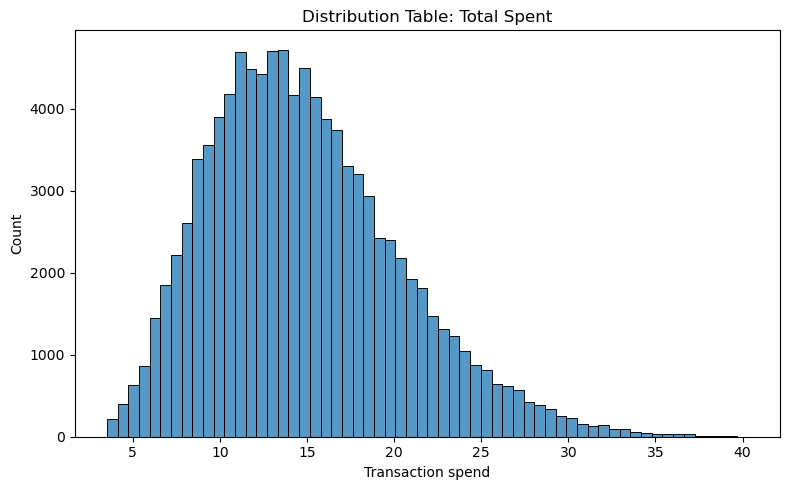

In [9]:
# Distribution Table of transaction spend.
plt.figure(figsize=(8, 5))
sns.histplot(df["total_spend"], bins=60)
plt.title("Distribution Table: Total Spent")
plt.xlabel("Transaction spend")
plt.tight_layout()
plt.show()

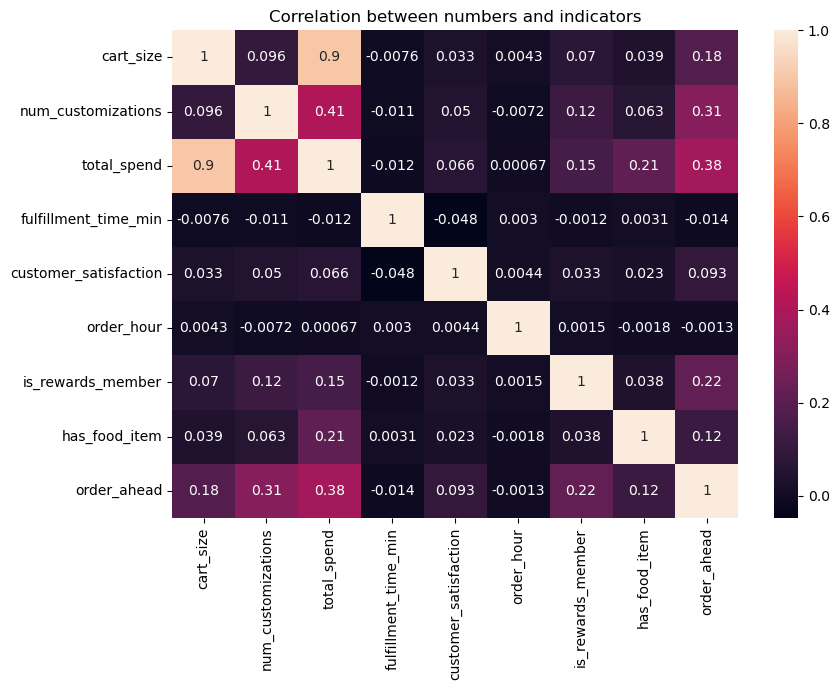

In [10]:
# Heatmap Correlation
CORRELATION_COLUMNS = [
    "cart_size", "num_customizations", "total_spend", "fulfillment_time_min",
    "customer_satisfaction", "order_hour", "is_rewards_member", "has_food_item", "order_ahead",]
correlation = df[CORRELATION_COLUMNS].astype(float).corr()
plt.figure(figsize=(9, 7))
sns.heatmap(correlation, annot=True)
plt.title("Correlation between numbers and indicators")
plt.tight_layout()
plt.show()

## 4. Linear regression

Linear regression is the baseline: it predicts a dollar amount. It uses order details known at order time. We train on 75% of the data and test on 25% (`random_state=42`).


In [11]:
REGRESSION_FEATURES = [
	"cart_size", "num_customizations", "has_food_item", "is_rewards_member", "order_ahead",
]
reg_X = df[REGRESSION_FEATURES].astype(float).to_numpy()
reg_y = df["total_spend"].to_numpy(dtype=float)

reg_X_train, reg_X_test, reg_y_train, reg_y_test = train_test_split(
	reg_X, reg_y, test_size=0.25, random_state=RANDOM_STATE
)

linear_model = LinearRegression().fit(reg_X_train, reg_y_train)
reg_predictions = linear_model.predict(reg_X_test)



In [12]:
linear_model

LinearRegression()

In [13]:
reg_predictions

array([18.07627172, 12.81371807, 12.17094679, ..., 10.87742756,
        6.69520942, 13.91653629])

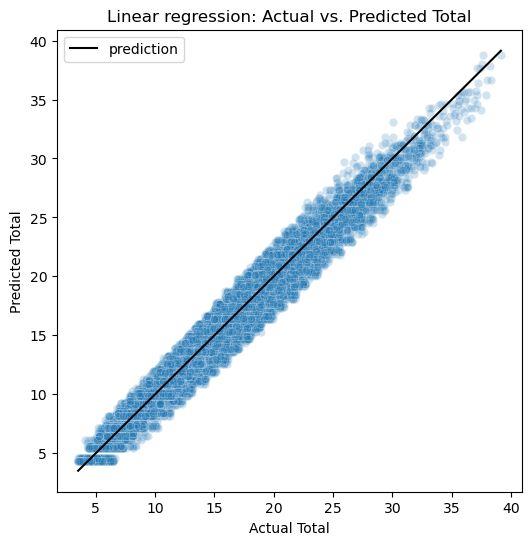

In [14]:
low = min(reg_y_test.min(), reg_predictions.min())
high = max(reg_y_test.max(), reg_predictions.max())

fig, ax = plt.subplots(figsize=(6, 6))
sns.scatterplot(x=reg_y_test, y=reg_predictions, alpha=0.2, ax=ax)
ax.plot([low, high], [low, high], linestyle="-", color="black", label="prediction")
ax.set(title="Linear regression: Actual vs. Predicted Total", xlabel="Actual Total", ylabel="Predicted Total",)
ax.legend()
plt.show()

## 5. KNN classification: Low, Medium, or High Spent

We predict a spend category (Low, Medium, or High) using the nearest neighbors in the training data.


### Make the X matrix of features and the y vector of labels

- Numeric features (`cart_size`, `num_customizations`, `order_hour`) are standardized after the split.
- Categorical and boolean features become 0/1 columns with `pd.get_dummies`.
- The label vector `y` is built after the split, so its cut points come only from the training data.


In [15]:
NUMERIC_FEATURES = ["cart_size", "num_customizations", "order_hour"]
CATEGORICAL_FEATURES = [
    "order_channel", "store_location_type", "region", "customer_age_group",
    "customer_gender", "drink_category", "day_of_week",
    "is_rewards_member", "has_food_item", "order_ahead",]
feature_frame = df[NUMERIC_FEATURES + CATEGORICAL_FEATURES]
X_features = pd.get_dummies(feature_frame, columns=CATEGORICAL_FEATURES, dtype=float)
FEATURE_NAMES = list(X_features.columns)
y_spend = df["total_spend"].to_numpy(dtype=float)


### train_test_split and divide the data

`train_test_split` gives a 75% training and 25% testing split with `random_state=42`. 
- The number columns are standardized with **training** which means and standard deviations only, and the same values are applied to the test set. 
- The 0/1 columns are left unchanged. 
- The labels are created from the training cut points.

In [16]:
X_train_frame, X_test_frame, spend_train, spend_test = train_test_split(
    X_features, y_spend, test_size=0.25, random_state=RANDOM_STATE
)
train_means = X_train_frame[NUMERIC_FEATURES].mean()
train_stds = X_train_frame[NUMERIC_FEATURES].std().replace(0.0, 1.0)


def standardize_numeric(frame: pd.DataFrame, means: pd.Series, stds: pd.Series) -> pd.DataFrame:
    return frame.assign(
        **{column: (frame[column] - means[column]) / stds[column] for column in NUMERIC_FEATURES}
    )


Xtrain = standardize_numeric(X_train_frame, train_means, train_stds).to_numpy(dtype=float)
Xtest = standardize_numeric(X_test_frame, train_means, train_stds).to_numpy(dtype=float)


def label_spend(spend: np.ndarray, low: float, high: float) -> np.ndarray:
    return np.where(spend <= low, "Low", np.where(spend <= high, "Medium", "High"))
low_threshold, high_threshold = np.quantile(spend_train, [1 / 3, 2 / 3])

ytrain = label_spend(spend_train, low_threshold, high_threshold)
ytest = label_spend(spend_test, low_threshold, high_threshold)

print(f"Low: {low_threshold}")
print(f"High: {high_threshold}")
print(f"Xtrain: {Xtrain.shape} | Xtest: {Xtest.shape}")
print(f"ytrain: {ytrain.shape} | ytest: {ytest.shape}")


Low: 11.98
High: 16.65
Xtrain: (75000, 43) | Xtest: (25000, 43)
ytrain: (75000,) | ytest: (25000,)


### Each row in X test
- Started by inspect the first test row here. 
- Later use this to repeat the process for every row.

In [17]:
TEST_INDEX = 0
print(f"Test row {TEST_INDEX} has {Xtest.shape[1]} features.")
print("Actual spend class:", ytest[TEST_INDEX], f"(total_spend = ${spend_test[TEST_INDEX]:})")


Test row 0 has 43 features.
Actual spend class: Medium (total_spend = $16.51)


### Distance from the test row to every training row
- The function returns one distance per training row, so the output has the same length as `Xtrain`.

In [18]:
def euclidean_distances(train: np.ndarray, query: np.ndarray) -> np.ndarray:return np.sqrt(np.sum((train - query) ** 2, axis=1))
distances_row0 = euclidean_distances(Xtrain, Xtest[TEST_INDEX])
print("Number of distances:", distances_row0.shape[0])
print("First 10 distances:", np.round(distances_row0[:10], 3))
print("Smallest distance:", round(float(distances_row0.min()), 3))


Number of distances: 75000
First 10 distances: [3.729 4.559 4.443 4.37  4.276 4.26  4.708 3.472 3.818 4.293]
Smallest distance: 1.571


### K smallest distances
- first sort the selected indices nearest first. 
- The indices matter because they point back to the labels in `ytrain`.
- Get the nearest `K_MAX = 15` neighbors once. 
- The K experiment in Section 5 reuses them, and the test set is not searched again for each value of K.

In [19]:
K = 5
K_MAX = 15
def nearest_indices(distances: np.ndarray, k: int) -> np.ndarray:
	if not 1 <= k <= distances.shape[0]:
		raise ValueError(f"k between 1 & {distances.shape[0]}, got {k}")
	candidates = np.argpartition(distances, k - 1)[:k]
	return candidates[np.argsort(distances[candidates], kind="stable")]
nearest_row0 = nearest_indices(distances_row0, K)
print(f"The {K} nearest rows:", nearest_row0)
print("The distances:", np.round(distances_row0[nearest_row0], 3))


The 5 nearest rows: [ 1016 16651 50025 26781 51026]
The distances: [1.571 1.586 1.586 1.63  1.89 ]


### Get the neighbor labels and vote

- `np.unique(..., return_counts=True)` counts the votes for each class, and the class with the most votes becomes the prediction. 
- If two classes tie, the tied class whose nearest neighbor is closest wins.

In [20]:
def majority_vote(neighbor_labels: np.ndarray) -> str:
	unique_labels, counts = np.unique(neighbor_labels, return_counts=True)
	tied_labels = unique_labels[counts == counts.max()]
	return str(neighbor_labels[np.isin(neighbor_labels, tied_labels)][0])
votes_row0 = ytrain[nearest_row0]

print("Neighbor labels:", votes_row0)
print("Predicted class:", majority_vote(votes_row0))
print("Actual class:   ", ytest[TEST_INDEX])

Neighbor labels: ['Medium' 'High' 'High' 'High' 'High']
Predicted class: High
Actual class:    Medium


### Repeat what was done for every row in X-test

In [21]:
neighbor_table = np.array(
	[nearest_indices(euclidean_distances(Xtrain, row), K_MAX) for row in Xtest]
)
predictions_array = np.array(
	[majority_vote(ytrain[row_neighbors[:K]]) for row_neighbors in neighbor_table],
	dtype="<U6",
)
print("Number of predictions:", len(predictions_array))
print("First 20 predictions:", predictions_array[:20])

Number of predictions: 25000
First 20 predictions: ['High' 'Medium' 'Medium' 'High' 'Low' 'High' 'Medium' 'Low' 'Low'
 'Medium' 'Low' 'High' 'Medium' 'Low' 'High' 'High' 'High' 'Low' 'Medium'
 'High']


---

doing brute-force KNN, which is O(n_test × n_train × n_features):

100,000 rows → 75,000 train × 25,000 test = 1.875 billion pairs.
After one-hot encoding there are 43 features (40 one-hot + 3 numeric).
That's ~1.875e9 × 43 ≈ 8e10 multiply-adds just for the distances (more like ~2–3× that with subtract/square/sum).
But the bigger problem is how it's written:

[nearest_indices(euclidean_distances(Xtrain, row), K_MAX) for row in Xtest]
It's a Python loop over 25,000 test rows, calling euclidean_distances one row at a time.
Each call does train - query, which allocates a 75,000 × 43 temporary array (~26 MB), then squares it (another ~26 MB). That's ~650 GB of memory allocation churn across the loop.
Then nearest_indices runs np.argpartition on 75,000 distances, 25,000 times.
So the cost is dominated by per-row Python overhead and repeated large allocations, not the actual math.

The K sweep (cell 37) is not the bottleneck — it reuses neighbor_table, so it only runs majority_vote 6 times over the existing neighbors.

Fix: batch the distances instead of looping per row
This keeps the same neighbor_table (nearest first) but uses a matrix multiply (‖a−b‖² = ‖a‖² + ‖b‖² − 2ab) in chunks:

train_sq = np.sum(Xtrain ** 2, axis=1)   # (n_train,)
test_sq = np.sum(Xtest ** 2, axis=1)     # (n_test,)

neighbor_table = np.empty((Xtest.shape[0], K_MAX), dtype=int)
chunk = 500  # rows of Xtest per batch; lower if memory is tight
for start in range(0, Xtest.shape[0], chunk):
    stop = start + chunk
    d2 = test_sq[start:stop, None] + train_sq[None, :] - 2.0 * (Xtest[start:stop] @ Xtrain.T)
    cand = np.argpartition(d2, K_MAX - 1, axis=1)[:, :K_MAX]
    rows = np.arange(stop - start)[:, None]
    order = np.argsort(d2[rows, cand], axis=1)
    neighbor_table[start:stop] = cand[rows, order]

predictions_array = np.array(
    [majority_vote(ytrain[row_neighbors[:K]]) for row_neighbors in neighbor_table],
    dtype="<U6",
)
The matmul is BLAS-optimized and multi-threaded, and there's no per-row 26 MB temporary. Expect a large speedup (often 10–50×).

Simpler alternative: let scikit-learn do it
from sklearn.neighbors import NearestNeighbors

nn = NearestNeighbors(n_neighbors=K_MAX, algorithm="brute", n_jobs=-1)
nn.fit(Xtrain)
neighbor_table = nn.kneighbors(Xtest, return_distance=False)

---

### Compare predictions with Y-Test and calculate for the accuracy for what we did

A match counts as correct, and accuracy is the number of correct predictions divided by the number of test rows. 
- The confusion matrix shows which classes get confused with each other. 
- Use NumPy directly so the metric is transparent.

In [22]:
# Accuracy: fraction of test rows where the predicted class matches the actual class.
correct_predictions = predictions_array == ytest
accuracy = correct_predictions.mean()
print(f"Correct predictions: {correct_predictions.sum():,} of {len(ytest):,}")
print(f"KNN accuracy (K={K}): {accuracy:.2%}")

CLASS_LABELS = np.array(["Low", "Medium", "High"])


def confusion_matrix_np(y_true, y_pred, labels):
    # Count how often each actual class was predicted as each class.
    index = {label: i for i, label in enumerate(labels)}
    matrix = np.zeros((len(labels), len(labels)), dtype=int)
    for true, pred in zip(y_true, y_pred):
        matrix[index[true], index[pred]] += 1
    return matrix


confusion = confusion_matrix_np(ytest, predictions_array, CLASS_LABELS)
diagonal = np.diag(confusion)
row_sums = confusion.sum(axis=1)
col_sums = confusion.sum(axis=0)
per_class = pd.DataFrame(
    {
        "actual_count": row_sums,
        "correct": diagonal,
        "recall": diagonal / row_sums,
        "precision": diagonal / col_sums,
    },
    index=CLASS_LABELS,
)
print(per_class)


Correct predictions: 18,963 of 25,000
KNN accuracy (K=5): 75.85%
        actual_count  correct    recall  precision
Low             8504     6895  0.810795   0.801837
Medium          8091     5340  0.659993   0.623978
High            8405     6728  0.800476   0.857835


### Choosing K

- A small K relies on a few neighbors and can be noisy. 
- A larger K smooths over local patterns. 
- The sweep reuses the neighbor table, so it does not redo any distances.

    K  accuracy
0   1   0.69604
1   3   0.73116
2   5   0.75852
3   7   0.77748
4   9   0.78824
5  15   0.80876
Best K in this experiment: 15 (accuracy 80.9%)


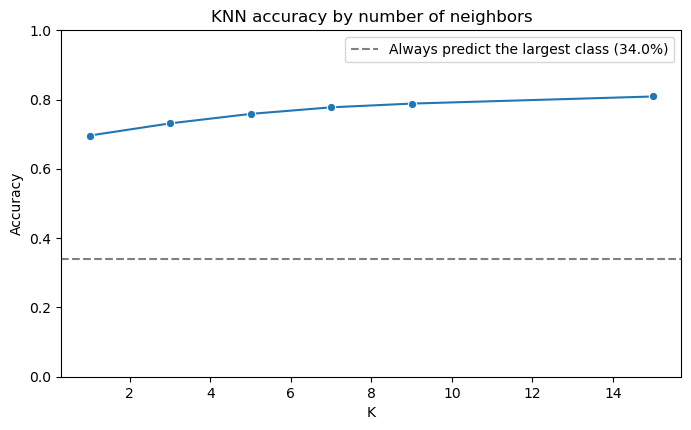

In [23]:
k_values = [1, 3, 5, 7, 9, 15]
k_results = pd.DataFrame(
	{
		"K": k_values,
		"accuracy": [
			np.mean(np.array([majority_vote(ytrain[row[:k]]) for row in neighbor_table]) == ytest)
			for k in k_values
		],
	}
)
print(k_results)

assert np.isclose(k_results.loc[k_results["K"] == K, "accuracy"].item(), accuracy), "K sweep disagrees with Task 9"
best_row = k_results.loc[k_results["accuracy"].idxmax()]

print(f"Best K in this experiment: {int(best_row['K'])} (accuracy {best_row['accuracy']:.1%})")


baseline = pd.Series(ytest).value_counts(normalize=True).max()
fig, ax = plt.subplots(figsize=(8, 4.5))

sns.lineplot(data=k_results, x="K", y="accuracy", marker="o", ax=ax)
ax.axhline(baseline, linestyle="--", color="grey", label=f"Always predict the largest class ({baseline:.1%})")
ax.set(title="KNN accuracy by number of neighbors", xlabel="K", ylabel="Accuracy", ylim=(0, 1))
ax.legend()
plt.show()


## What do we know now?
- Each of the six drink categories earns between 16.5% and 16.8% of revenue, and average order values fall between $14.82 and $14.91. 
- Refresher ranks first, but the gap between first and last is only about a quarter of a percentage point.
- his is not **Meaningful** information.

## Can KNN predict the spend category?
**Can we predict whether a Starbucks transaction will be a low, medium, or high-value purchase based on customer behavior, order characteristics, and purchasing patterns?**
- A heatmap of the confusion matrix can let us see.

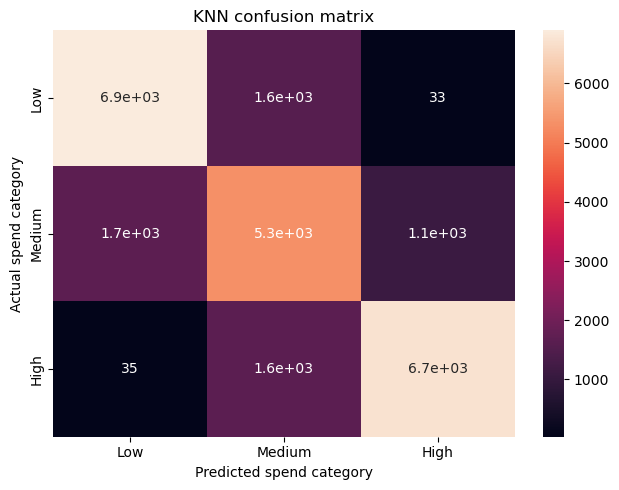

KNN accuracy: 75.9%
Majority-class baseline: 34.0%
Difference from baseline: +41.8 percentage points


In [25]:
fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(
	confusion,
	annot=True,
	xticklabels=CLASS_LABELS,
	yticklabels=CLASS_LABELS,
	ax=ax,
)
ax.set(
	title=f"KNN confusion matrix",
	xlabel="Predicted spend category",
	ylabel="Actual spend category",
)
plt.tight_layout()
plt.show()

print(f"KNN accuracy: {accuracy:.1%}")
print(f"Majority-class baseline: {baseline:.1%}")
print(f"Difference from baseline: {(accuracy - baseline) * 100:+.1f} percentage points")
